# 04 - PCA, K-Means Clustering and Neural Network (TensorFlow / Keras)

1. **PCA** - how many independent "directions" of variation are hidden in the 21 plant sensors?
2. **K-Means** - can we find typical operating modes of the plant without using the silica value?
3. **Neural network in Keras** - can a non-linear model predict silica better than the linear models?

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression, Lasso

import tensorflow as tf
from tensorflow import keras

from src import data
from src.plot_style import setup, save, COLORS
setup()

In [2]:
hourly = data.load_hourly()
train, test = data.time_split(hourly)
sensors = data.PROCESS_VARS
print(len(hourly), "hours,", len(sensors), "sensor variables")

3947 hours, 21 sensor variables


## Part A - Principal Component Analysis
PCA finds new axes (principal components) that are linear combinations of the original variables.
PC1 points in the direction of maximum variance, PC2 the next one at right angles to PC1, and so on.
The components are the eigenvectors of the covariance matrix of the standardised data; the eigenvalues
give the variance along each one. We standardise first because the sensors have very different units.

PC1 explains 34.5%, PC2 16.8%
Components needed for 80 % of variance: 6,  for 95 %: 13  (out of 21)


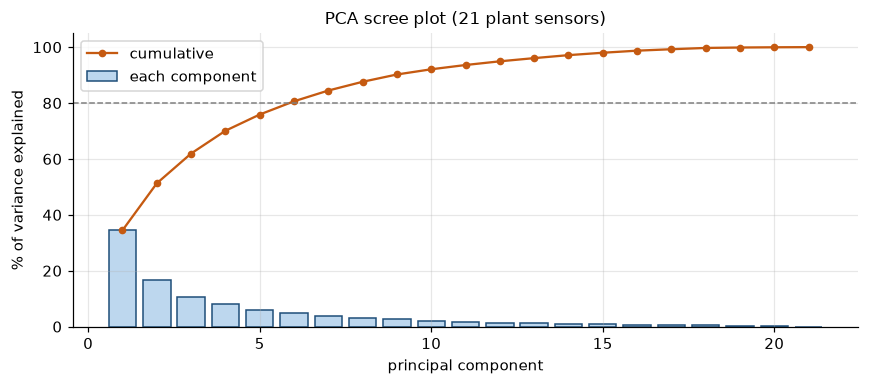

In [3]:
sc_pca = StandardScaler().fit(train[sensors])
Z_train = sc_pca.transform(train[sensors])
Z_all = sc_pca.transform(hourly[sensors])

pca = PCA().fit(Z_train)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n80, n95 = int(np.argmax(cum >= 0.80)) + 1, int(np.argmax(cum >= 0.95)) + 1
print(f"PC1 explains {evr[0]:.1%}, PC2 {evr[1]:.1%}")
print(f"Components needed for 80 % of variance: {n80},  for 95 %: {n95}  (out of {len(sensors)})")

fig, ax = plt.subplots(figsize=(8, 3.6))
k = np.arange(1, len(evr) + 1)
ax.bar(k, evr * 100, color=COLORS["light"], edgecolor=COLORS["main"], label="each component")
ax.plot(k, cum * 100, "o-", color=COLORS["accent"], ms=4, label="cumulative")
ax.axhline(80, color="grey", ls="--", lw=1)
ax.set_xlabel("principal component"); ax.set_ylabel("% of variance explained")
ax.set_title("PCA scree plot (21 plant sensors)"); ax.legend()
save(fig, "fig20_pca_scree")
plt.show()

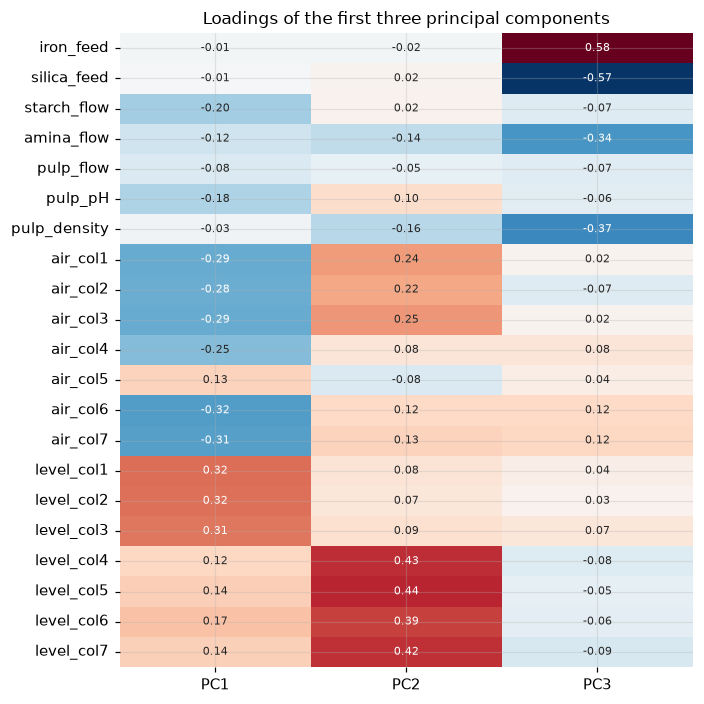

In [4]:
loadings = pd.DataFrame(pca.components_[:3].T, index=sensors, columns=["PC1", "PC2", "PC3"])
fig, ax = plt.subplots(figsize=(6.5, 6.5))
sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax, cbar=False)
ax.set_title("Loadings of the first three principal components")
save(fig, "fig21_pca_loadings")
plt.show()

Reading the loadings:
- **PC1 (about 35 %)** has negative loadings on the air flows of columns 1-4, 6, 7 and positive loadings on the
  levels of columns 1-3. It describes the operators turning the air down while the level in the first columns
  goes up (and the reverse) - one "air vs level" knob that moves many sensors together.
- **PC2 (about 17 %)** is mainly the levels of columns 4-7 moving together.
- **PC3** is the feed quality: iron in the feed (+) against silica in the feed (-), plus pulp density
  and amine flow.
- So the 21 sensors are far from independent - the strong correlations we saw in the heatmap are
  compressed into a handful of components (6 components keep 80 % of the variance).

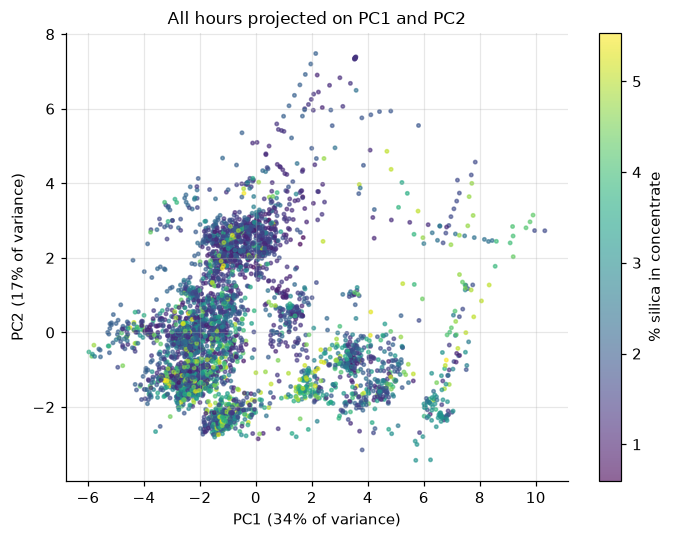

In [5]:
pcs = pca.transform(Z_all)
fig, ax = plt.subplots(figsize=(6.5, 5))
s = ax.scatter(pcs[:, 0], pcs[:, 1], c=hourly[data.TARGET], cmap="viridis", s=5, alpha=0.6)
plt.colorbar(s, ax=ax, label="% silica in concentrate")
ax.set_xlabel(f"PC1 ({evr[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({evr[1]:.0%} of variance)")
ax.set_title("All hours projected on PC1 and PC2")
save(fig, "fig22_pca_scatter")
plt.show()

High and low silica hours are mixed together on the PC1-PC2 plane. This agrees with what we found before:
the biggest variations in the sensors are **not** the ones that decide silica.

**PCA + regression (principal component regression).** We replace the 21 sensors by the first k
components and fit a linear regression (still with the two lab-lag features added):

In [6]:
pcr_rows = []
lag_sc = StandardScaler().fit(train[data.LAB_LAGS])
L_train, L_test = lag_sc.transform(train[data.LAB_LAGS]), lag_sc.transform(test[data.LAB_LAGS])
P_train, P_test = pca.transform(Z_train), pca.transform(sc_pca.transform(test[sensors]))
for n in [0, 2, 5, n80, n95, len(sensors)]:
    Xtr = np.c_[P_train[:, :n], L_train]
    Xte = np.c_[P_test[:, :n], L_test]
    m = LinearRegression().fit(Xtr, train[data.TARGET])
    pcr_rows.append({"principal components used": n, "inputs in total": n + 2,
                     "test R2": r2_score(test[data.TARGET], m.predict(Xte))})
pcr = pd.DataFrame(pcr_rows)
os.makedirs(data.RES_DIR, exist_ok=True)
pcr.round(4).to_csv(os.path.join(data.RES_DIR, "pca_regression.csv"), index=False)
pcr.round(3)

,principal components used,inputs in total,test R2
0,0,2,0.646
1,2,4,0.644
2,5,7,0.640
3,6,8,0.640
4,13,15,0.631
5,21,23,0.617


With all 21 components we get back plain MLR (same R2 as notebook 02). Keeping only the first few
components cuts the number of inputs a lot and the test R2 even goes up slightly - dropping the
low-variance components acts like regularization. With 0 components we are left with the lab values
only, which again scores about the same: the sensor information mostly does not carry over to the test period.

## Part B - K-Means clustering of operating modes
K-means groups the hours into k clusters so that hours in a cluster have similar sensor values.
It repeats two steps until nothing changes: (1) assign each hour to the nearest centroid,
(2) move each centroid to the mean of its hours. It minimises the within-cluster sum of squares (inertia).

We cluster on the standardised **sensors only** - silica is not used, so this is unsupervised.
Afterwards we check if the clusters have different silica.

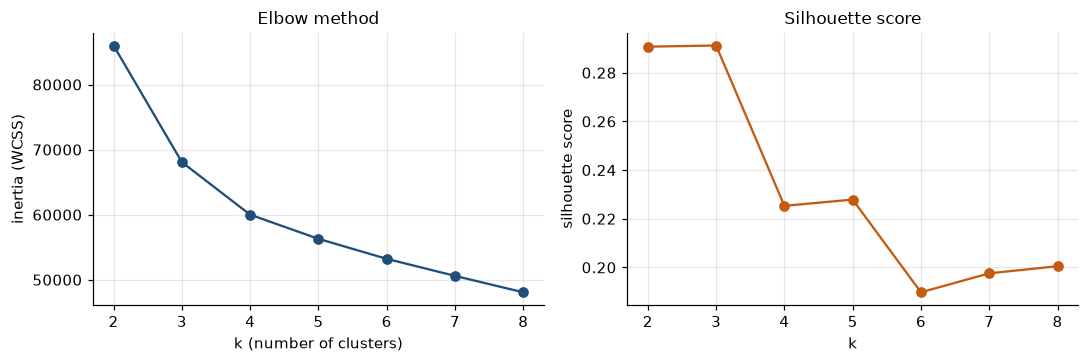

,k,inertia,silhouette
0,2,85998.0,0.291
1,3,68078.0,0.291
2,4,60006.0,0.225
3,5,56295.0,0.228
4,6,53221.0,0.190
5,7,50602.0,0.198
6,8,48079.0,0.200


In [7]:
ks = range(2, 9)
inertia, sil = [], []
for k_ in ks:
    km_ = KMeans(n_clusters=k_, n_init=10, random_state=42).fit(Z_all)
    inertia.append(km_.inertia_)
    sil.append(silhouette_score(Z_all, km_.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(list(ks), inertia, "o-", color=COLORS["main"])
axes[0].set_xlabel("k (number of clusters)"); axes[0].set_ylabel("inertia (WCSS)"); axes[0].set_title("Elbow method")
axes[1].plot(list(ks), sil, "o-", color=COLORS["accent"])
axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette score"); axes[1].set_title("Silhouette score")
save(fig, "fig23_kmeans_elbow")
plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia), "silhouette": np.round(sil, 3)})

The elbow is not very sharp (real plant data rarely has clean clusters). k = 2 and k = 3 have the same,
highest silhouette score (0.29), and after k = 3 the inertia drops much more slowly. We choose **k = 3**:
it gives more detail than k = 2 at no loss in cluster quality, and the three groups are easy to interpret.

In [8]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Z_all)
hourly["cluster"] = km.labels_
# number the clusters by their average silica, so the names are stable: 0 = lowest silica
order = hourly.groupby("cluster")[data.TARGET].mean().sort_values().index
mapping = {old: new for new, old in enumerate(order)}
hourly["cluster"] = hourly["cluster"].map(mapping)

profile = hourly.groupby("cluster").agg(
    hours=(data.TARGET, "size"),
    mean_silica=(data.TARGET, "mean"),
    off_spec_share=("off_spec", "mean"),
    air_col1_3=("air_col1", "mean"),
    level_col1_3=("level_col1", "mean"),
    level_col4_7=("level_col5", "mean"),
    amina_flow=("amina_flow", "mean"),
    starch_flow=("starch_flow", "mean"),
    pulp_pH=("pulp_pH", "mean"),
    silica_feed=("silica_feed", "mean"),
)
profile.round(3).to_csv(os.path.join(data.RES_DIR, "kmeans_cluster_profile.csv"))
profile.round(2)

,hours,mean_silica,off_spec_share,air_col1_3,level_col1_3,level_col4_7,amina_flow,starch_flow,pulp_pH,silica_feed
cluster,,,,,,,,,,
0,2436,2.24,0.22,290.20,476.40,416.14,502.47,3085.00,9.87,13.87
1,690,2.30,0.23,299.74,499.29,404.61,463.02,2936.81,9.63,17.91
2,821,2.58,0.34,239.45,668.55,457.71,469.67,2067.59,9.60,14.79


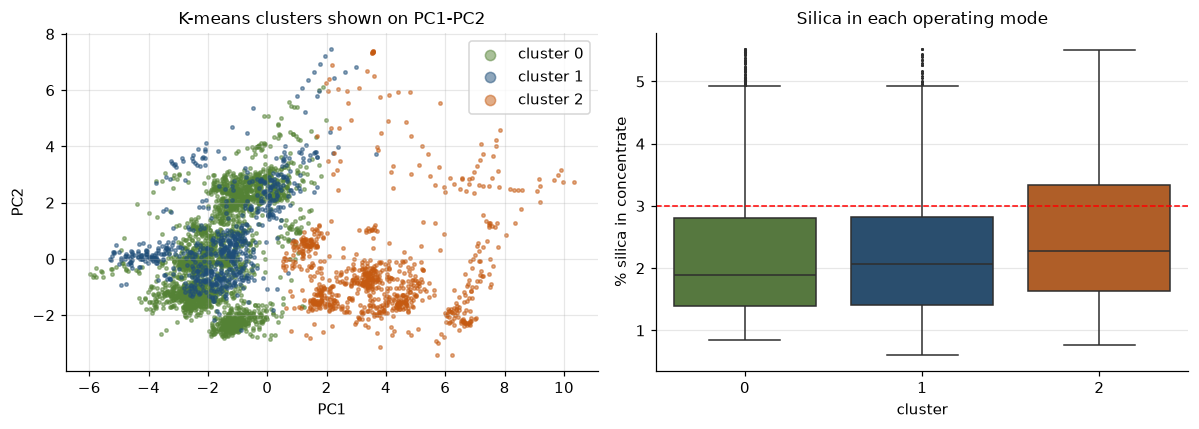

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
palette = [COLORS["good"], COLORS["main"], COLORS["accent"]]
for c in range(3):
    m = hourly["cluster"] == c
    axes[0].scatter(pcs[m.values, 0], pcs[m.values, 1], s=5, alpha=0.5, color=palette[c], label=f"cluster {c}")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].set_title("K-means clusters shown on PC1-PC2")
axes[0].legend(markerscale=3)
sns.boxplot(data=hourly, x="cluster", y=data.TARGET, hue="cluster", palette=palette, ax=axes[1], fliersize=1, legend=False)
axes[1].axhline(data.OFF_SPEC_LIMIT, color="red", ls="--", lw=1)
axes[1].set_ylabel("% silica in concentrate"); axes[1].set_title("Silica in each operating mode")
save(fig, "fig24_kmeans_clusters")
plt.show()

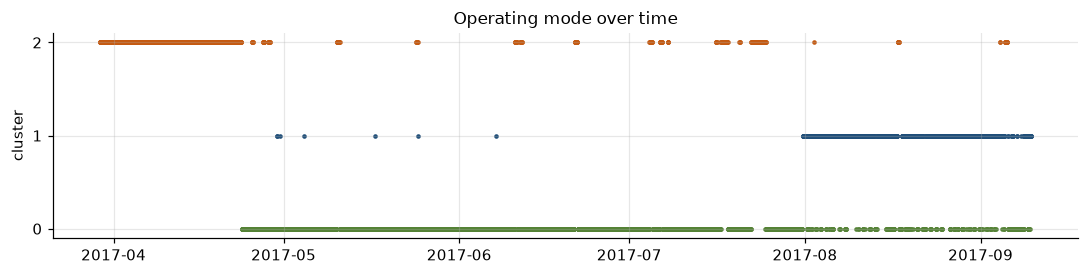

In [10]:
fig, ax = plt.subplots(figsize=(10, 2.6))
for c in range(3):
    m = hourly["cluster"] == c
    ax.scatter(hourly.index[m], np.full(m.sum(), c), s=4, color=palette[c])
ax.set_yticks([0, 1, 2]); ax.set_ylabel("cluster"); ax.set_title("Operating mode over time")
save(fig, "fig25_clusters_over_time")
plt.show()

The clusters correspond to long periods of plant operation (they are not random), i.e. real operating modes:

| Mode | Hours | What is different | Silica | Off-spec |
|---|---|---|---|---|
| 0 - normal | about 2,400 | air in columns 1-3 near 290 Nm3/h, normal levels | 2.24 % | 22 % |
| 1 - high-silica feed | about 700 | feed silica about 18 % (vs 14 %), lower pH and amine | 2.30 % | 23 % |
| 2 - low air / high level | about 800 | air in columns 1-3 cut to about 240, level in columns 1-3 about 670 mm, less starch | 2.58 % | 34 % |

Silica was never used to make the clusters, yet mode 2 has clearly more off-spec hours. This plant uses
**reverse flotation**: the amine collector makes the silica (quartz) particles stick to air bubbles and float
away in the froth, while starch keeps the iron oxide down so it leaves as the concentrate. Less air means fewer
bubbles to carry silica out, so more silica stays in the concentrate. This agrees with the negative
coefficients of the air flows in notebooks 02 and 03.

Mode 1 is interesting too: the feed has more silica, but the concentrate is almost as clean as in mode 0,
so the plant handled the harder feed well.

## Part C - Neural network with TensorFlow / Keras
A feed-forward network (multi-layer perceptron) for the regression problem, same 23 inputs as notebook 02.

- Input layer: 23 standardised features
- Hidden layer 1: 32 neurons, ReLU
- Hidden layer 2: 16 neurons, ReLU
- Output: 1 neuron, linear (predicted % silica)
- Loss: mean squared error, optimizer: Adam (a gradient-descent variant)
- Early stopping on a validation set (the last 20 % of the training period)

We train two versions to show the effect of regularization:
- **Network A** - light L2 penalty (0.001), no dropout
- **Network B** - stronger L2 penalty (0.03) and dropout 0.2 after each hidden layer

In [11]:
sc_nn = StandardScaler().fit(train[data.FEATURES])
Xtr_all = sc_nn.transform(train[data.FEATURES]); ytr_all = train[data.TARGET].values
Xte = sc_nn.transform(test[data.FEATURES]); yte = test[data.TARGET].values
cut = int(len(Xtr_all) * 0.8)                       # validation = last 20 % of training period (no shuffling)
Xtr, Xval, ytr, yval = Xtr_all[:cut], Xtr_all[cut:], ytr_all[:cut], ytr_all[cut:]

def build_model(l2=1e-3, dropout=0.0):
    reg = keras.regularizers.l2(l2)
    layers = [keras.Input(shape=(Xtr.shape[1],))]
    for units in (32, 16):
        layers.append(keras.layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(1))
    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
    return model

def train_model(l2, dropout, seed=42):
    tf.keras.utils.set_random_seed(seed)
    model = build_model(l2, dropout)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)
    hist = model.fit(Xtr, ytr, validation_data=(Xval, yval), epochs=400, batch_size=32,
                     callbacks=[stop], verbose=0)
    return model, hist

build_model(0.03, 0.2).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313 (5.13 KB)

 Trainable params: 1,313 (5.13 KB)

 Non-trainable params: 0 (0.00 B)

Network A: stopped after 66 epochs, test R2 = -0.266
Network B: stopped after 95 epochs, test R2 = 0.605


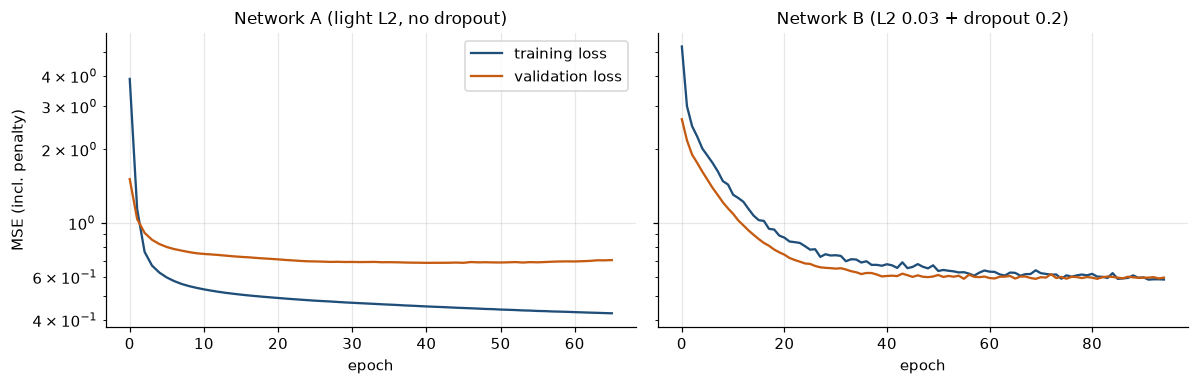

In [12]:
nn_a, hist_a = train_model(l2=1e-3, dropout=0.0)
nn_b, hist_b = train_model(l2=3e-2, dropout=0.2)
pred_a = nn_a.predict(Xte, verbose=0).ravel()
pred_nn = nn_b.predict(Xte, verbose=0).ravel()
print(f"Network A: stopped after {len(hist_a.history['loss'])} epochs, test R2 = {r2_score(yte, pred_a):.3f}")
print(f"Network B: stopped after {len(hist_b.history['loss'])} epochs, test R2 = {r2_score(yte, pred_nn):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, hist, title in [(axes[0], hist_a, "Network A (light L2, no dropout)"), (axes[1], hist_b, "Network B (L2 0.03 + dropout 0.2)")]:
    ax.plot(hist.history["loss"], label="training loss", color=COLORS["main"])
    ax.plot(hist.history["val_loss"], label="validation loss", color=COLORS["accent"])
    ax.set_xlabel("epoch"); ax.set_title(title); ax.set_yscale("log")
axes[0].set_ylabel("MSE (incl. penalty)"); axes[0].legend()
save(fig, "fig26_nn_learning_curve")
plt.show()

Network A fits the training period well but fails badly on the test period (negative R2): it has
~1,300 weights and learns sensor patterns that do not repeat later. In July-September some sensors
move outside the range seen in training, and an over-fitted network extrapolates badly there.
Network B, with stronger regularization, is much more stable.

Neural network results also depend on the random starting weights, so we repeat Network B with
five different seeds:

In [13]:
seed_r2 = [r2_score(yte, train_model(3e-2, 0.2, seed=s)[0].predict(Xte, verbose=0).ravel()) for s in range(5)]
print("Network B test R2 over 5 seeds:", np.round(seed_r2, 3))
print(f"mean = {np.mean(seed_r2):.3f}, std = {np.std(seed_r2):.3f}")

# Lasso refit on the same inputs for a direct comparison (same alpha search idea as notebook 02)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
lasso = GridSearchCV(Lasso(max_iter=20000), {"alpha": np.logspace(-4, 0, 25)}, cv=TimeSeriesSplit(5),
                     scoring="neg_root_mean_squared_error").fit(Xtr_all, ytr_all).best_estimator_
pred_lasso = lasso.predict(Xte)

def scores(y, p):
    return {"R2": r2_score(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p)}

nn_res = pd.DataFrame({"Baseline (last hour)": scores(yte, test["silica_prev_hr"].values),
                       "Lasso": scores(yte, pred_lasso),
                       "Network A (light regularization)": scores(yte, pred_a),
                       "Network B (L2 + dropout)": scores(yte, pred_nn)}).T
nn_res.round(4).to_csv(os.path.join(data.RES_DIR, "neural_network_results.csv"))
nn_res.round(3)

Network B test R2 over 5 seeds: [0.613 0.564 0.603 0.607 0.616]
mean = 0.601, std = 0.019


,R2,RMSE,MAE
Baseline (last hour),0.608,0.711,0.433
Lasso,0.639,0.681,0.471
Network A (light regularization),-0.266,1.276,0.978
Network B (L2 + dropout),0.605,0.713,0.519


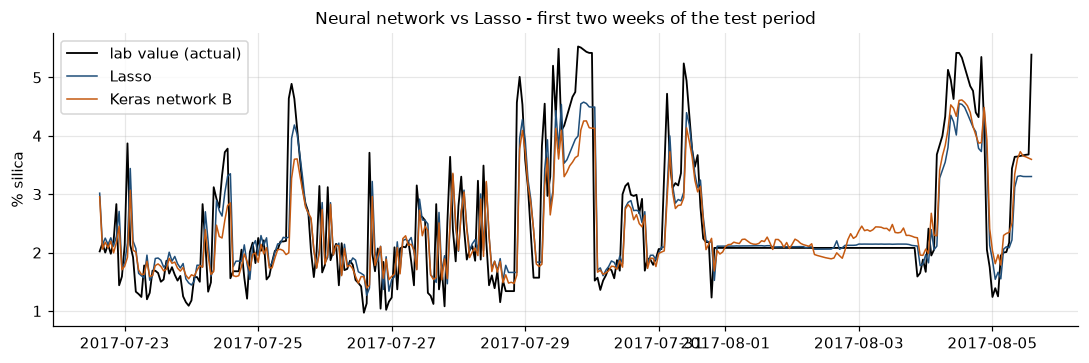

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.4))
w = slice(0, 24 * 14)
ax.plot(test.index[w], yte[w], color="k", lw=1.2, label="lab value (actual)")
ax.plot(test.index[w], pred_lasso[w], color=COLORS["main"], lw=1, label="Lasso")
ax.plot(test.index[w], pred_nn[w], color=COLORS["accent"], lw=1, label="Keras network B")
ax.set_ylabel("% silica"); ax.set_title("Neural network vs Lasso - first two weeks of the test period"); ax.legend()
save(fig, "fig27_nn_vs_lasso")
plt.show()

## Conclusions
- **PCA:** the 21 sensors behave like a much smaller number of independent variables; the main
  direction of variation (PC1, the air flows) is not strongly linked to silica.
- **K-Means:** without seeing silica, k-means splits the six months into three operating modes that run
  for long periods and have clearly different average silica and off-spec share.
- **Neural network:** without enough regularization the Keras network over-fits and is worse than
  predicting the average. With L2 + dropout it becomes reasonable, but it is still a little below Lasso
  and changes from seed to seed. With about 2,700 training hours and mostly linear relationships, a bigger
  model does not help - the simpler, explainable model is the better choice for the plant.